# 🚆 RailWay AI: Deep Learning Domain Text Classifier
### Project: Railway Domain Question-Answering Assistant
**Model**: 2-Layer Bidirectional LSTM with Custom Learned Embeddings (Trained from Scratch)  
**Task**: 6-Class Railway Inquiries Intent Classification (`WAITLIST`, `RAC`, `PNR_STATUS`, `CANCELLATION`, `REFUND`, `BOOKING_ISSUES`)  
**Framework**: PyTorch, Pandas, Scikit-Learn, Matplotlib, Seaborn  

---

### 📋 Academic Integrity & Dataset Disclosure
> **DISCLOSURE**: The dataset utilized in this project (`railway_questions_dataset.csv`) contains **600 curated and synthetically formulated passenger inquiries** modeled after official Indian Railways passenger reservation rules, IRCTC ticketing guidelines, and real-world travel scenarios.
> 
> **It is NOT official or private CRIS/IRCTC passenger log data.** It contains zero Personally Identifiable Information (PII) or confidential transaction records.
> 
> **MODEL INTEGRITY**: The classifier is trained **from scratch using randomly initialized weights** via PyTorch. **No pre-trained LLMs, HuggingFace transformers, or external AI APIs** are utilized during training or inference.


## 1. Setup & Environment Verification
Verify active Python environment, detect compute hardware (GPU / CPU), and set deterministic seeds.


In [1]:
import sys
import os
import json
import re
import random
import shutil

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Set deterministic seeds for full reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Version: {torch.__version__}")
print(f"Active Compute Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Hardware: {torch.cuda.get_device_name(0)}")


PyTorch Version: 2.14.1+cpu
Active Compute Device: cpu


## 2. Dataset Loading & Provenance
Loads `railway_questions_dataset.csv`.
If running in a fresh Google Colab session where the CSV has not been uploaded, this cell automatically synthesizes the complete 600-sample dataset directly into `/content/railway_questions_dataset.csv`, ensuring top-to-bottom execution without `FileNotFoundError`.


In [2]:
# Candidate paths across local and Google Colab environments
candidate_paths = [
    "railway_questions_dataset.csv",
    os.path.join("data", "railway_questions_dataset.csv"),
    "/content/railway_questions_dataset.csv",
    "/content/data/railway_questions_dataset.csv"
]

csv_path = None
for p in candidate_paths:
    if os.path.exists(p):
        csv_path = p
        break

if csv_path is not None:
    print(f"Loading existing dataset from: {csv_path}")
    df = pd.read_csv(csv_path)
else:
    print("Dataset CSV not found in session storage. Generating full 600-sample synthetic benchmark dataset...")
    # Self-contained 600-sample benchmark dataset
    raw_data = [
  [
    "What does GNWL mean in Indian Railways?",
    "WAITLIST"
  ],
  [
    "My ticket status shows WL 45, what are my chances of confirmation?",
    "WAITLIST"
  ],
  [
    "Can I travel in sleeper class with a waitlisted e-ticket?",
    "WAITLIST"
  ],
  [
    "What is the difference between GNWL and RLWL?",
    "WAITLIST"
  ],
  [
    "Does waitlist ticket get auto cancelled after chart preparation?",
    "WAITLIST"
  ],
  [
    "What is Remote Location Waiting List RLWL?",
    "WAITLIST"
  ],
  [
    "What is Pooled Quota Waiting List PQWL?",
    "WAITLIST"
  ],
  [
    "Can I board the train with an offline counter waitlist ticket?",
    "WAITLIST"
  ],
  [
    "Why is PQWL confirmation chance lower than GNWL?",
    "WAITLIST"
  ],
  [
    "How does the waitlist clearance priority work in IRCTC?",
    "WAITLIST"
  ],
  [
    "Will my waitlisted ticket be upgraded during chart preparation?",
    "WAITLIST"
  ],
  [
    "What happens if my Tatkal ticket remains in waitlist?",
    "WAITLIST"
  ],
  [
    "Is it legal to travel on a train with an unconfirmed online waitlist ticket?",
    "WAITLIST"
  ],
  [
    "How many waiting list tickets can get confirmed in 3rd AC?",
    "WAITLIST"
  ],
  [
    "What does WL/WL mean on an IRCTC ticket?",
    "WAITLIST"
  ],
  [
    "What is the difference between booking status and current status for waitlist?",
    "WAITLIST"
  ],
  [
    "Can a waitlisted passenger get an RAC berth after charting?",
    "WAITLIST"
  ],
  [
    "Why does my waitlist number not change for several days?",
    "WAITLIST"
  ],
  [
    "What is Roadside Station Waiting List RSWL?",
    "WAITLIST"
  ],
  [
    "Can two passengers on one PNR travel if one is confirmed and one is waitlist?",
    "WAITLIST"
  ],
  [
    "If my ticket is in waitlist will I be charged clerkage fee?",
    "WAITLIST"
  ],
  [
    "How does chart preparation affect waitlist status?",
    "WAITLIST"
  ],
  [
    "Is there any quota to convert waiting list to confirmed berth?",
    "WAITLIST"
  ],
  [
    "Can TTE allow waitlisted passenger if seats become vacant en route?",
    "WAITLIST"
  ],
  [
    "What is the maximum waiting list limit allowed for booking?",
    "WAITLIST"
  ],
  [
    "Will waitlisted ticket amount be credited back automatically?",
    "WAITLIST"
  ],
  [
    "My status is WL 12 for Rajdhani Express, will it clear?",
    "WAITLIST"
  ],
  [
    "What is the probability of confirmation for GNWL 10 in sleeper?",
    "WAITLIST"
  ],
  [
    "What does REGRET status mean when booking waitlisted tickets?",
    "WAITLIST"
  ],
  [
    "Can I cancel my waitlist ticket before chart preparation?",
    "WAITLIST"
  ],
  [
    "Do waitlist tickets get confirmed against Tatkal cancellations?",
    "WAITLIST"
  ],
  [
    "How does emergency quota HO affect the waiting list movement?",
    "WAITLIST"
  ],
  [
    "What happens to waiting list passengers if the train is cancelled?",
    "WAITLIST"
  ],
  [
    "What is NOSB in waitlisted or partially confirmed tickets?",
    "WAITLIST"
  ],
  [
    "Can I change boarding point on a waitlisted ticket?",
    "WAITLIST"
  ],
  [
    "Why do some waitlisted tickets show WL instead of seat number?",
    "WAITLIST"
  ],
  [
    "If ticket is WL at final chart does passenger get full refund?",
    "WAITLIST"
  ],
  [
    "Can I file TDR for waitlist ticket that didn't confirm?",
    "WAITLIST"
  ],
  [
    "Are waitlist passengers provided bedrolls in AC coaches?",
    "WAITLIST"
  ],
  [
    "How to know if a waitlisted ticket has reached RAC?",
    "WAITLIST"
  ],
  [
    "Does premium tatkal have a waiting list option?",
    "WAITLIST"
  ],
  [
    "Difference between WL and CKWL in Tatkal booking?",
    "WAITLIST"
  ],
  [
    "What is the confirmation pattern for senior citizen waitlist?",
    "WAITLIST"
  ],
  [
    "Can waitlist ticket be transferred to a family member?",
    "WAITLIST"
  ],
  [
    "What does CNF/WL indicate on ticket printout?",
    "WAITLIST"
  ],
  [
    "My ticket is WL 5 in 1st AC, does 1st AC waitlist move fast?",
    "WAITLIST"
  ],
  [
    "Can I buy food from pantry car if I have waitlisted ticket?",
    "WAITLIST"
  ],
  [
    "What is the penalty if caught travelling on an online waitlisted ticket?",
    "WAITLIST"
  ],
  [
    "Why did my waitlist ticket get dropped from the final chart?",
    "WAITLIST"
  ],
  [
    "How does chart 2 update the waiting list?",
    "WAITLIST"
  ],
  [
    "Is waitlist confirmation guaranteed if VIP quota is not used?",
    "WAITLIST"
  ],
  [
    "Can I travel in general unreserved coach with counter WL ticket?",
    "WAITLIST"
  ],
  [
    "What is ladies quota waiting list LDWL?",
    "WAITLIST"
  ],
  [
    "How to predict waitlist confirmation using historical trends?",
    "WAITLIST"
  ],
  [
    "Why is my current status still WL when chart is already prepared?",
    "WAITLIST"
  ],
  [
    "Can waitlisted passenger enter railway station platform?",
    "WAITLIST"
  ],
  [
    "What happens if partially waitlisted ticket is cancelled?",
    "WAITLIST"
  ],
  [
    "Can waitlist ticket be converted to Tatkal ticket?",
    "WAITLIST"
  ],
  [
    "Does waitlisted ticket provide insurance coverage?",
    "WAITLIST"
  ],
  [
    "What are the rules for travelling with e-ticket having WL status?",
    "WAITLIST"
  ],
  [
    "How does GNWL move when confirmed passengers cancel seats?",
    "WAITLIST"
  ],
  [
    "Is RLWL confirmation probability higher than PQWL?",
    "WAITLIST"
  ],
  [
    "What happens if all passengers on e-ticket remain in waitlist?",
    "WAITLIST"
  ],
  [
    "Can a waitlisted passenger get sleeper berth if RAC passengers do not turn up?",
    "WAITLIST"
  ],
  [
    "What does WL 15 / WL 8 mean in current status?",
    "WAITLIST"
  ],
  [
    "Why is my waiting list number increasing instead of decreasing?",
    "WAITLIST"
  ],
  [
    "How many hours before departure does waiting list chart finalize?",
    "WAITLIST"
  ],
  [
    "Can TTE give vacant berth to waitlisted passenger on counter ticket?",
    "WAITLIST"
  ],
  [
    "What is the difference between General Waiting List and Tatkal Waiting List?",
    "WAITLIST"
  ],
  [
    "Does waitlist clear faster during festival rush or off season?",
    "WAITLIST"
  ],
  [
    "What does WL mean in Indian train reservation?",
    "WAITLIST"
  ],
  [
    "Is there any senior citizen preference in waitlist clearance?",
    "WAITLIST"
  ],
  [
    "How does chart preparation resolve waiting list queue?",
    "WAITLIST"
  ],
  [
    "Can I book waitlist ticket if status shows REGRET?",
    "WAITLIST"
  ],
  [
    "Why does waitlist booking close after reaching a certain number?",
    "WAITLIST"
  ],
  [
    "What is DPWL Defense Quota Waiting List in railway booking?",
    "WAITLIST"
  ],
  [
    "Will waitlist ticket confirm if train has extra coaches attached?",
    "WAITLIST"
  ],
  [
    "How to track if waitlist moved to RAC or confirmed?",
    "WAITLIST"
  ],
  [
    "What is RLGN waitlist quota in Indian Railways?",
    "WAITLIST"
  ],
  [
    "Can waitlist ticket passenger stay in railway waiting room?",
    "WAITLIST"
  ],
  [
    "Why did my waitlist ticket not clear despite many vacant seats in chart?",
    "WAITLIST"
  ],
  [
    "What does WL 1 / WL 1 mean on my e-ticket?",
    "WAITLIST"
  ],
  [
    "Are waitlist passengers eligible for free food during train delay?",
    "WAITLIST"
  ],
  [
    "Can I travel on waitlist ticket in Garib Rath trains?",
    "WAITLIST"
  ],
  [
    "Does waitlist ticket get confirmed in Vande Bharat express?",
    "WAITLIST"
  ],
  [
    "What happens if 1 passenger is confirmed and 2 are in waiting list?",
    "WAITLIST"
  ],
  [
    "Can counter waitlist ticket be cancelled at any PRS window?",
    "WAITLIST"
  ],
  [
    "Why does IRCTC show waitlist available when seats are zero?",
    "WAITLIST"
  ],
  [
    "What is the clearance order among GNWL, RLWL, and PQWL?",
    "WAITLIST"
  ],
  [
    "How many WL seats clear on average in sleeper class?",
    "WAITLIST"
  ],
  [
    "Can I board 3AC coach if my counter ticket is in waitlist?",
    "WAITLIST"
  ],
  [
    "What is the meaning of CKWL in tatkal waitlist?",
    "WAITLIST"
  ],
  [
    "Will my waitlisted ticket be refunded if not confirmed?",
    "WAITLIST"
  ],
  [
    "Why does waitlist not move until the day of journey?",
    "WAITLIST"
  ],
  [
    "Is waitlisted e-ticket valid for travel after chart preparation?",
    "WAITLIST"
  ],
  [
    "How does quota release affect waitlist confirmation?",
    "WAITLIST"
  ],
  [
    "Can waitlisted passenger travel in unreserved general compartment?",
    "WAITLIST"
  ],
  [
    "What happens to waitlist passengers when train is diverted?",
    "WAITLIST"
  ],
  [
    "What is the rule for travelling with waiting list ticket?",
    "WAITLIST"
  ],
  [
    "Does waitlist clearance happen automatically in computer system?",
    "WAITLIST"
  ],
  [
    "What does RAC mean in Indian Railways?",
    "RAC"
  ],
  [
    "Can I legally board and travel on a train with an RAC ticket?",
    "RAC"
  ],
  [
    "Do RAC passengers get a full sleeping berth or half seat?",
    "RAC"
  ],
  [
    "How are berths allocated to RAC ticket holders?",
    "RAC"
  ],
  [
    "Which berth is usually given to RAC passengers?",
    "RAC"
  ],
  [
    "Will an RAC ticket definitely get confirmed before departure?",
    "RAC"
  ],
  [
    "Can two passengers share one Side Lower berth in RAC?",
    "RAC"
  ],
  [
    "Do RAC passengers in AC coaches get complete bedroll and blanket?",
    "RAC"
  ],
  [
    "What happens if my RAC ticket does not get confirmed into CNF?",
    "RAC"
  ],
  [
    "Can I cancel an RAC ticket after the chart is prepared?",
    "RAC"
  ],
  [
    "What are the cancellation charges for an RAC ticket?",
    "RAC"
  ],
  [
    "Can TTE allot a full berth to an RAC passenger if someone doesn't turn up?",
    "RAC"
  ],
  [
    "How does an RAC ticket move to confirmed status during charting?",
    "RAC"
  ],
  [
    "Is meal included for RAC passengers in Rajdhani and Shatabdi trains?",
    "RAC"
  ],
  [
    "What is the difference between RAC and Waitlist WL?",
    "RAC"
  ],
  [
    "Can an RAC passenger sleep comfortably during daytime journey?",
    "RAC"
  ],
  [
    "Can I file TDR if I don't want to travel on an RAC seat?",
    "RAC"
  ],
  [
    "What happens if one passenger is confirmed and second is RAC on same PNR?",
    "RAC"
  ],
  [
    "How many RAC seats are there in a Sleeper coach?",
    "RAC"
  ],
  [
    "How many RAC berths are reserved in 3rd AC coach?",
    "RAC"
  ],
  [
    "Can RAC passenger claim full berth if co-passenger gets off early?",
    "RAC"
  ],
  [
    "At what time is the final RAC seat allocation finalized?",
    "RAC"
  ],
  [
    "Do RAC passengers have to show ID proof to TTE on board?",
    "RAC"
  ],
  [
    "Can an RAC ticket holder be denied boarding by TTE?",
    "RAC"
  ],
  [
    "Why does my ticket show RAC 15 / RAC 12?",
    "RAC"
  ],
  [
    "What does booking status RAC and current status CNF mean?",
    "RAC"
  ],
  [
    "Can pregnant women or senior citizens request full berth instead of RAC?",
    "RAC"
  ],
  [
    "What happens if an RAC passenger does not occupy the berth within 10 minutes?",
    "RAC"
  ],
  [
    "Are children allotted half RAC seat or full seat?",
    "RAC"
  ],
  [
    "Can RAC tickets be booked under Tatkal quota?",
    "RAC"
  ],
  [
    "Can I change boarding station if my ticket is RAC?",
    "RAC"
  ],
  [
    "What is the refund rule if RAC ticket is cancelled before 30 minutes of train departure?",
    "RAC"
  ],
  [
    "Is bedroll fee refunded if RAC passenger is not given bedroll?",
    "RAC"
  ],
  [
    "How does second chart affect RAC ticket confirmation?",
    "RAC"
  ],
  [
    "Can an RAC passenger get an upper berth upon confirmation?",
    "RAC"
  ],
  [
    "What is the difference between RAC in Sleeper vs RAC in AC 3 Tier?",
    "RAC"
  ],
  [
    "Can an RAC passenger travel without fear of penalty from ticket collector?",
    "RAC"
  ],
  [
    "Do RAC ticket holders get SMS notification when berth is confirmed?",
    "RAC"
  ],
  [
    "Can I cancel one passenger out of two RAC passengers on IRCTC?",
    "RAC"
  ],
  [
    "What are the clerkage charges for cancelling RAC ticket?",
    "RAC"
  ],
  [
    "Is RAC available in Vande Bharat chair car trains?",
    "RAC"
  ],
  [
    "Why does IRCTC issue RAC instead of waitlist directly?",
    "RAC"
  ],
  [
    "Can RAC passenger switch berths with confirmed passenger mutually?",
    "RAC"
  ],
  [
    "What if TTE allots my RAC berth to another passenger?",
    "RAC"
  ],
  [
    "How to file TDR for RAC ticket when passenger did not travel?",
    "RAC"
  ],
  [
    "Can an RAC ticket be transferred to blood relatives?",
    "RAC"
  ],
  [
    "Does travel insurance apply to RAC ticket holders?",
    "RAC"
  ],
  [
    "Can RAC passengers sit in the dining car in special trains?",
    "RAC"
  ],
  [
    "What is the minimum hours before departure to cancel an RAC ticket?",
    "RAC"
  ],
  [
    "Can RAC ticket holder request side upper berth?",
    "RAC"
  ],
  [
    "How many RAC tickets get confirmed on average before charting?",
    "RAC"
  ],
  [
    "If RAC passenger gets down at intermediate station can co-passenger use full berth?",
    "RAC"
  ],
  [
    "What happens if train is delayed more than 3 hours and passenger has RAC?",
    "RAC"
  ],
  [
    "Can I get full refund on RAC ticket if train is cancelled by Railways?",
    "RAC"
  ],
  [
    "Is RAC allotment done automatically by the computerized reservation system?",
    "RAC"
  ],
  [
    "What does RAC mean in Shatabdi executive chair car?",
    "RAC"
  ],
  [
    "Can two male and female strangers be allotted same RAC side lower berth?",
    "RAC"
  ],
  [
    "Will RAC ticket be eligible for free food if train is delayed?",
    "RAC"
  ],
  [
    "How can I track real time movement of my RAC status?",
    "RAC"
  ],
  [
    "Can an RAC passenger upgrade to higher class with TTE?",
    "RAC"
  ],
  [
    "What is the meaning of RAC in train ticket?",
    "RAC"
  ],
  [
    "Do RAC passengers get sitting accommodation guaranteed?",
    "RAC"
  ],
  [
    "Why is RAC allotted only on Side Lower berth?",
    "RAC"
  ],
  [
    "Can two passengers sit together on RAC berth?",
    "RAC"
  ],
  [
    "What is the clerkage fee if RAC ticket is cancelled 2 hours before train?",
    "RAC"
  ],
  [
    "Can RAC passenger ask TTE for vacant upper berth?",
    "RAC"
  ],
  [
    "Does RAC guarantee that I won't be deboarded from train?",
    "RAC"
  ],
  [
    "How does RAC get converted into confirmed CNF berth?",
    "RAC"
  ],
  [
    "What happens if RAC passenger does not show up on board?",
    "RAC"
  ],
  [
    "Are RAC passengers given pillows and bed sheets in 2AC?",
    "RAC"
  ],
  [
    "Can an RAC passenger sleep during the night journey?",
    "RAC"
  ],
  [
    "What does RAC 1 / RAC 1 mean on reservation chart?",
    "RAC"
  ],
  [
    "How many hours before departure can I cancel an RAC ticket?",
    "RAC"
  ],
  [
    "Can an RAC ticket be cancelled after chart preparation?",
    "RAC"
  ],
  [
    "What happens to RAC tickets in case of train cancellation?",
    "RAC"
  ],
  [
    "Is RAC allowed in Tejas Express trains?",
    "RAC"
  ],
  [
    "Can senior citizen traveling on RAC seat request lower berth?",
    "RAC"
  ],
  [
    "Why does RAC passenger only get half berth?",
    "RAC"
  ],
  [
    "What does status RAC 5 mean in Indian Railways?",
    "RAC"
  ],
  [
    "Can TTE reallocate unallotted RAC berth to general passenger?",
    "RAC"
  ],
  [
    "How does chart 1 upgrade RAC passengers?",
    "RAC"
  ],
  [
    "What is the refund amount for cancelling RAC ticket before 30 mins?",
    "RAC"
  ],
  [
    "Can RAC ticket holder board from intermediate station?",
    "RAC"
  ],
  [
    "Do RAC passengers get meal in Duronto Express?",
    "RAC"
  ],
  [
    "Why do two passengers have to share one side lower in RAC?",
    "RAC"
  ],
  [
    "Can I file TDR for RAC ticket if I did not travel?",
    "RAC"
  ],
  [
    "What is the difference between RAC in 3E and 3A?",
    "RAC"
  ],
  [
    "Is RAC confirmation prioritized over waitlist confirmation?",
    "RAC"
  ],
  [
    "Can RAC ticket holder occupy upper berth during daytime?",
    "RAC"
  ],
  [
    "What is the rule for RAC co-passenger leaving mid journey?",
    "RAC"
  ],
  [
    "How does TTE assign vacant berths to RAC passengers?",
    "RAC"
  ],
  [
    "Can RAC e-ticket be cancelled after chart is prepared?",
    "RAC"
  ],
  [
    "Do children get full bedroll on RAC ticket in 3rd AC?",
    "RAC"
  ],
  [
    "Why does IRCTC provide RAC option instead of direct confirmation?",
    "RAC"
  ],
  [
    "What are the rights of an RAC passenger on Indian Railways?",
    "RAC"
  ],
  [
    "Can RAC passenger sleep between 10 PM and 6 AM?",
    "RAC"
  ],
  [
    "What is the cancellation charge on RAC ticket before departure?",
    "RAC"
  ],
  [
    "How to know if my RAC seat became a confirmed berth?",
    "RAC"
  ],
  [
    "Is RAC passenger permitted in AC first class?",
    "RAC"
  ],
  [
    "What happens if both RAC passengers want to sleep on same berth?",
    "RAC"
  ],
  [
    "How do I check my 10 digit PNR status online?",
    "PNR_STATUS"
  ],
  [
    "Where is the PNR number located on an IRCTC e-ticket?",
    "PNR_STATUS"
  ],
  [
    "What is the difference between booking status and current PNR status?",
    "PNR_STATUS"
  ],
  [
    "When is the first reservation chart prepared before train departure?",
    "PNR_STATUS"
  ],
  [
    "What is the second chart in Indian Railways and when is it finalized?",
    "PNR_STATUS"
  ],
  [
    "My PNR status shows CNF B4 23 MB, what does MB mean?",
    "PNR_STATUS"
  ],
  [
    "What does LB, MB, UB, SL, SU mean in PNR berth allocation?",
    "PNR_STATUS"
  ],
  [
    "Why does PNR status show Charting Done but no coach is assigned?",
    "PNR_STATUS"
  ],
  [
    "How can I check PNR status via SMS on mobile phone?",
    "PNR_STATUS"
  ],
  [
    "Can I check PNR status without internet connection?",
    "PNR_STATUS"
  ],
  [
    "Why does my PNR show Flushed or Invalid PNR error?",
    "PNR_STATUS"
  ],
  [
    "For how many months is a PNR number valid after the journey date?",
    "PNR_STATUS"
  ],
  [
    "How often does PNR status update before charting?",
    "PNR_STATUS"
  ],
  [
    "What does CAN / MOD mean in PNR current status column?",
    "PNR_STATUS"
  ],
  [
    "Does PNR status tell me which platform the train will arrive on?",
    "PNR_STATUS"
  ],
  [
    "Can anyone check my personal passenger details using my PNR number?",
    "PNR_STATUS"
  ],
  [
    "How to check if chart preparation is completed for my train?",
    "PNR_STATUS"
  ],
  [
    "Why does PNR enquiry show Train Cancelled?",
    "PNR_STATUS"
  ],
  [
    "What does CNF S5 45 mean in railway ticket status?",
    "PNR_STATUS"
  ],
  [
    "How many passenger names can be associated with a single PNR?",
    "PNR_STATUS"
  ],
  [
    "Can PNR status be checked at railway station automatic kiosks?",
    "PNR_STATUS"
  ],
  [
    "What is the official Indian Railways website to check PNR enquiry?",
    "PNR_STATUS"
  ],
  [
    "Why did coach number not display on PNR status until 4 hours before train?",
    "PNR_STATUS"
  ],
  [
    "Does PNR status change after train starts running from originating station?",
    "PNR_STATUS"
  ],
  [
    "Can I track train running status directly from my PNR number?",
    "PNR_STATUS"
  ],
  [
    "What does REL status signify in PNR inquiry?",
    "PNR_STATUS"
  ],
  [
    "Why does PNR say Passenger Not Turned Up in current status?",
    "PNR_STATUS"
  ],
  [
    "How to check berth number for 1st AC ticket through PNR status?",
    "PNR_STATUS"
  ],
  [
    "Why are coupe and cabin numbers in 1AC allotted only after chart prep?",
    "PNR_STATUS"
  ],
  [
    "Can I get PNR status alerts directly on WhatsApp?",
    "PNR_STATUS"
  ],
  [
    "What does W/L 32 / RAC 4 mean in PNR progression?",
    "PNR_STATUS"
  ],
  [
    "Is PNR number generated immediately after payment completion?",
    "PNR_STATUS"
  ],
  [
    "Can PNR status show seat number if chart is not yet prepared?",
    "PNR_STATUS"
  ],
  [
    "Where to find PNR number on printed counter ticket?",
    "PNR_STATUS"
  ],
  [
    "How can I verify if my ticket is genuine using PNR status?",
    "PNR_STATUS"
  ],
  [
    "What does PNR stand for in railway reservation?",
    "PNR_STATUS"
  ],
  [
    "Can I know who is sharing the coupe with me using PNR enquiry?",
    "PNR_STATUS"
  ],
  [
    "Why does PNR inquiry return 'No such PNR found' after train departure?",
    "PNR_STATUS"
  ],
  [
    "How to check PNR status on official 139 railway helpline number?",
    "PNR_STATUS"
  ],
  [
    "Does PNR inquiry show departure delay and rescheduled time?",
    "PNR_STATUS"
  ],
  [
    "What does NC or Not Connected mean in PNR server error?",
    "PNR_STATUS"
  ],
  [
    "Can PNR be retrieved using passenger mobile number or transaction ID?",
    "PNR_STATUS"
  ],
  [
    "How to download revised e-ticket after PNR status changes from WL to CNF?",
    "PNR_STATUS"
  ],
  [
    "Why does PNR status display different details on third party apps vs IRCTC?",
    "PNR_STATUS"
  ],
  [
    "What is the meaning of CC coach in PNR status?",
    "PNR_STATUS"
  ],
  [
    "What does EC stand for in Jan Shatabdi or Vande Bharat PNR status?",
    "PNR_STATUS"
  ],
  [
    "Can I check boarding point change status in PNR enquiry?",
    "PNR_STATUS"
  ],
  [
    "Does PNR status show infant details booked without berth?",
    "PNR_STATUS"
  ],
  [
    "How soon is second chart prepared before train departure from station?",
    "PNR_STATUS"
  ],
  [
    "Why is PNR status showing RAC even after train has departed?",
    "PNR_STATUS"
  ],
  [
    "Can I verify meal preference opt-in using my PNR status?",
    "PNR_STATUS"
  ],
  [
    "What does DEPARTED status mean on the PNR tracker?",
    "PNR_STATUS"
  ],
  [
    "How do foreign tourists check PNR status for FT quota tickets?",
    "PNR_STATUS"
  ],
  [
    "Does PNR search provide information on connecting train guarantee?",
    "PNR_STATUS"
  ],
  [
    "Why did PNR show CNF originally but now displays RAC?",
    "PNR_STATUS"
  ],
  [
    "Can I check luggage booking status using my ticket PNR?",
    "PNR_STATUS"
  ],
  [
    "What does G1, G2 coach notation mean in Garib Rath PNR status?",
    "PNR_STATUS"
  ],
  [
    "Why is my PNR showing WL when friends on same train booked confirmed?",
    "PNR_STATUS"
  ],
  [
    "How to interpret current status column in railway PNR output?",
    "PNR_STATUS"
  ],
  [
    "Can I get PNR confirmation prediction directly from official railway site?",
    "PNR_STATUS"
  ],
  [
    "Where is the 10 digit PNR printed on railway ticket?",
    "PNR_STATUS"
  ],
  [
    "How to check PNR status on Indian Railways passenger enquiry portal?",
    "PNR_STATUS"
  ],
  [
    "What does Charting Status: Chart Not Prepared mean in PNR?",
    "PNR_STATUS"
  ],
  [
    "What does Charting Status: Chart Prepared indicate on PNR enquiry?",
    "PNR_STATUS"
  ],
  [
    "How many hours before train departure is the chart prepared?",
    "PNR_STATUS"
  ],
  [
    "Why does PNR status show coach B1 berth 12 for confirmed ticket?",
    "PNR_STATUS"
  ],
  [
    "What does Lower Berth LB stand for in PNR seat allotment?",
    "PNR_STATUS"
  ],
  [
    "What does Side Upper SU stand for in train PNR enquiry?",
    "PNR_STATUS"
  ],
  [
    "Can I check my PNR status by calling 139 customer care?",
    "PNR_STATUS"
  ],
  [
    "Why does PNR status say PNR flushed after journey is completed?",
    "PNR_STATUS"
  ],
  [
    "How to know coach position and platform from PNR number?",
    "PNR_STATUS"
  ],
  [
    "What does CNF mean in current PNR status?",
    "PNR_STATUS"
  ],
  [
    "What does CAN mean in PNR status details?",
    "PNR_STATUS"
  ],
  [
    "Why did my PNR status change from waitlist to RAC after charting?",
    "PNR_STATUS"
  ],
  [
    "How can I track my PNR live status update on IRCTC?",
    "PNR_STATUS"
  ],
  [
    "What is second chart preparation timing before train departure?",
    "PNR_STATUS"
  ],
  [
    "Why is coupe number not allotted in 1AC PNR status until 4 hours before train?",
    "PNR_STATUS"
  ],
  [
    "Can I check PNR status using IRCTC Rail Connect mobile app?",
    "PNR_STATUS"
  ],
  [
    "Does PNR inquiry show passenger name or only age and gender?",
    "PNR_STATUS"
  ],
  [
    "How long is PNR enquiry active on the railway reservation server?",
    "PNR_STATUS"
  ],
  [
    "What does status code RAC 12 mean on PNR check?",
    "PNR_STATUS"
  ],
  [
    "Can I check PNR status for tickets booked at railway reservation counter?",
    "PNR_STATUS"
  ],
  [
    "What is the meaning of booking status vs current status in PNR report?",
    "PNR_STATUS"
  ],
  [
    "Why is my PNR status showing RAC even though I booked confirmed seat?",
    "PNR_STATUS"
  ],
  [
    "How to verify if PNR is genuine and not fake?",
    "PNR_STATUS"
  ],
  [
    "Does PNR status show if catering meal is opted or not?",
    "PNR_STATUS"
  ],
  [
    "What does WL 23 mean on PNR status output screen?",
    "PNR_STATUS"
  ],
  [
    "Why does PNR show chart prepared but no berth number for waitlisted passenger?",
    "PNR_STATUS"
  ],
  [
    "How to check seat allocation in final chart via PNR?",
    "PNR_STATUS"
  ],
  [
    "Can I check train schedule and delay from PNR number?",
    "PNR_STATUS"
  ],
  [
    "What does Passenger Name Record PNR contain in railway database?",
    "PNR_STATUS"
  ],
  [
    "Why does PNR status say Train Rescheduled?",
    "PNR_STATUS"
  ],
  [
    "How many digits are there in a railway PNR number?",
    "PNR_STATUS"
  ],
  [
    "What does M1, M2 coach signify in 3E AC economy PNR status?",
    "PNR_STATUS"
  ],
  [
    "Where do I enter PNR number on indianrail.gov.in website?",
    "PNR_STATUS"
  ],
  [
    "Can PNR status be sent via SMS by sending PNR to 139?",
    "PNR_STATUS"
  ],
  [
    "Why does PNR status show status as Confirmed but coach as NA?",
    "PNR_STATUS"
  ],
  [
    "What is the significance of 10 digits in PNR number?",
    "PNR_STATUS"
  ],
  [
    "How does reservation chart preparation update the PNR status?",
    "PNR_STATUS"
  ],
  [
    "Can I check PNR current status after chart is prepared?",
    "PNR_STATUS"
  ],
  [
    "What are the cancellation charges for a confirmed Sleeper class ticket?",
    "CANCELLATION"
  ],
  [
    "How much cancellation fee is deducted for 3rd AC confirmed ticket?",
    "CANCELLATION"
  ],
  [
    "What is the deduction if 2nd AC ticket is cancelled 48 hours before departure?",
    "CANCELLATION"
  ],
  [
    "Can I cancel my train ticket after chart preparation?",
    "CANCELLATION"
  ],
  [
    "How can I cancel a ticket online booked through IRCTC portal?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation rule between 48 hours and 12 hours before departure?",
    "CANCELLATION"
  ],
  [
    "What percentage is deducted if ticket is cancelled between 12 hours and 4 hours before train?",
    "CANCELLATION"
  ],
  [
    "Is any refund given if confirmed ticket is cancelled less than 4 hours before departure?",
    "CANCELLATION"
  ],
  [
    "What are the rules for cancelling a confirmed Tatkal ticket?",
    "CANCELLATION"
  ],
  [
    "Can I get any refund on cancelling a confirmed Tatkal ticket?",
    "CANCELLATION"
  ],
  [
    "How to cancel railway counter ticket online via IRCTC portal?",
    "CANCELLATION"
  ],
  [
    "Within how many hours must counter ticket passenger collect refund at PRS counter?",
    "CANCELLATION"
  ],
  [
    "Can I cancel ticket for only one passenger on a group ticket?",
    "CANCELLATION"
  ],
  [
    "What are the cancellation charges for RAC tickets before 30 minutes of departure?",
    "CANCELLATION"
  ],
  [
    "What is the clerkage fee for cancelling a waitlisted railway ticket?",
    "CANCELLATION"
  ],
  [
    "How do I file a TDR Ticket Deposit Receipt for ticket cancellation?",
    "CANCELLATION"
  ],
  [
    "Can I cancel my ticket if the train is running late by more than 3 hours?",
    "CANCELLATION"
  ],
  [
    "Do I get full refund without cancellation charges if train is delayed over 3 hours?",
    "CANCELLATION"
  ],
  [
    "What happens if Indian Railways cancels the train due to fog or accident?",
    "CANCELLATION"
  ],
  [
    "Do I need to cancel my e-ticket if the train is cancelled by Railways?",
    "CANCELLATION"
  ],
  [
    "Can I cancel my train ticket at the station if booked online?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation charge for Executive Class EC in Vande Bharat?",
    "CANCELLATION"
  ],
  [
    "Can Tatkal waitlist ticket be cancelled and what are the charges?",
    "CANCELLATION"
  ],
  [
    "What is the deadline for filing TDR for a cancelled train?",
    "CANCELLATION"
  ],
  [
    "Can I cancel ticket if AC is not working during the train journey?",
    "CANCELLATION"
  ],
  [
    "What are the rules for cancellation if passenger is downgraded from 2AC to 3AC?",
    "CANCELLATION"
  ],
  [
    "Can I cancel ticket after train has already started its journey?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation charge for Second Seating 2S class ticket?",
    "CANCELLATION"
  ],
  [
    "What are the charges for cancelling First AC 1A confirmed ticket?",
    "CANCELLATION"
  ],
  [
    "How to cancel circular journey ticket issued by Indian Railways?",
    "CANCELLATION"
  ],
  [
    "Can I cancel a ticket booked under Senior Citizen concession?",
    "CANCELLATION"
  ],
  [
    "What happens to catering fee when ticket is cancelled?",
    "CANCELLATION"
  ],
  [
    "Is GST refunded on train ticket cancellation?",
    "CANCELLATION"
  ],
  [
    "What happens if one passenger cancels in a partially confirmed family ticket?",
    "CANCELLATION"
  ],
  [
    "How to file TDR if passenger could not board train due to late connecting train?",
    "CANCELLATION"
  ],
  [
    "Can a confirmed ticket be cancelled by sending SMS to 139?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation fee for Premium Tatkal confirmed ticket?",
    "CANCELLATION"
  ],
  [
    "Can I cancel my return journey ticket separately in round trip booking?",
    "CANCELLATION"
  ],
  [
    "How many hours before chart preparation can I cancel without 50 percent deduction?",
    "CANCELLATION"
  ],
  [
    "What are the conditions where Indian Railways grants 100 percent refund on cancellation?",
    "CANCELLATION"
  ],
  [
    "What happens if train route is diverted and passenger does not want to travel?",
    "CANCELLATION"
  ],
  [
    "Can I cancel my ticket if boarding station was changed earlier?",
    "CANCELLATION"
  ],
  [
    "What is the penalty for cancelling child ticket without berth?",
    "CANCELLATION"
  ],
  [
    "How to cancel railway ticket through IRCTC mobile application?",
    "CANCELLATION"
  ],
  [
    "Can agent cancel my ticket without my OTP verification?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation OTP verification process for counter tickets?",
    "CANCELLATION"
  ],
  [
    "Is convenience fee refunded upon ticket cancellation?",
    "CANCELLATION"
  ],
  [
    "Can I cancel ticket if wrong name or age was entered during booking?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation policy for Defence quota tickets?",
    "CANCELLATION"
  ],
  [
    "How to file TDR when coach attached is not of the booked class?",
    "CANCELLATION"
  ],
  [
    "Can I cancel my ticket if train terminates short of destination?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation deadline for morning trains whose chart is prepared at night?",
    "CANCELLATION"
  ],
  [
    "Do I get refund if I cancel ticket after missing the train?",
    "CANCELLATION"
  ],
  [
    "What is the maximum time limit to cancel counter ticket online before train?",
    "CANCELLATION"
  ],
  [
    "How are cancellation charges calculated for multiple passengers on same PNR?",
    "CANCELLATION"
  ],
  [
    "Can travel insurance premium be refunded on ticket cancellation?",
    "CANCELLATION"
  ],
  [
    "What are the cancellation rules for festival special trains?",
    "CANCELLATION"
  ],
  [
    "How to cancel railway pass ticket issued to government employees?",
    "CANCELLATION"
  ],
  [
    "Can I withdraw cancellation request after clicking confirm on IRCTC?",
    "CANCELLATION"
  ],
  [
    "What documents are required to cancel a counter ticket at reservation window?",
    "CANCELLATION"
  ],
  [
    "What is the flat cancellation charge for Sleeper class before 48 hours?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation charge for 3rd AC coach before 48 hours?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation fee for 2nd AC ticket before 48 hours?",
    "CANCELLATION"
  ],
  [
    "What is the deduction for cancelling 1AC ticket more than 48 hours prior?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation fee between 48 hours and 12 hours of departure?",
    "CANCELLATION"
  ],
  [
    "What percentage of fare is deducted between 12 hours and 4 hours before train?",
    "CANCELLATION"
  ],
  [
    "Can a confirmed railway ticket be cancelled less than 4 hours before departure?",
    "CANCELLATION"
  ],
  [
    "Why is there no refund for confirmed ticket cancelled after chart preparation?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation fee for cancelling RAC ticket before 30 minutes?",
    "CANCELLATION"
  ],
  [
    "Can I cancel my waitlist ticket online before chart preparation?",
    "CANCELLATION"
  ],
  [
    "What are the charges for cancelling a waitlisted ticket?",
    "CANCELLATION"
  ],
  [
    "How to file TDR online for ticket cancellation on IRCTC?",
    "CANCELLATION"
  ],
  [
    "Can I cancel confirmed Tatkal ticket and get refund?",
    "CANCELLATION"
  ],
  [
    "What happens to ticket cancellation if train is cancelled by Railways?",
    "CANCELLATION"
  ],
  [
    "Do I have to cancel ticket manually if train is cancelled by Railways?",
    "CANCELLATION"
  ],
  [
    "How can I cancel my counter ticket through IRCTC portal?",
    "CANCELLATION"
  ],
  [
    "What is the time limit to collect refund after cancelling counter ticket online?",
    "CANCELLATION"
  ],
  [
    "Can I cancel only 1 passenger on a 4 passenger PNR?",
    "CANCELLATION"
  ],
  [
    "What are the cancellation rules for Premium Tatkal tickets?",
    "CANCELLATION"
  ],
  [
    "Can I cancel ticket if train is delayed by more than 3 hours?",
    "CANCELLATION"
  ],
  [
    "How to cancel railway e-ticket from IRCTC website step by step?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation charge for AC Chair Car CC class?",
    "CANCELLATION"
  ],
  [
    "Can ticket be cancelled after train has departed from the boarding station?",
    "CANCELLATION"
  ],
  [
    "What are the TDR cancellation filing rules for AC failure?",
    "CANCELLATION"
  ],
  [
    "How to cancel ticket if passenger could not travel due to illness?",
    "CANCELLATION"
  ],
  [
    "What happens to catering fee when confirmed train ticket is cancelled?",
    "CANCELLATION"
  ],
  [
    "Is GST deducted when cancelling AC train tickets?",
    "CANCELLATION"
  ],
  [
    "Can I cancel round trip ticket partially?",
    "CANCELLATION"
  ],
  [
    "What is clerkage fee on cancellation of railway waitlist ticket?",
    "CANCELLATION"
  ],
  [
    "How to cancel ticket on IRCTC Rail Connect app?",
    "CANCELLATION"
  ],
  [
    "Can confirmed ticket cancellation be undone once confirmed?",
    "CANCELLATION"
  ],
  [
    "What are cancellation charges for Vande Bharat chair car?",
    "CANCELLATION"
  ],
  [
    "What is the rule for cancelling ticket if route is diverted?",
    "CANCELLATION"
  ],
  [
    "How to file TDR if coach was not attached to train?",
    "CANCELLATION"
  ],
  [
    "Can I cancel ticket if TTE does not give lower berth?",
    "CANCELLATION"
  ],
  [
    "What is the cancellation deduction for 2S second seating?",
    "CANCELLATION"
  ],
  [
    "Why did IRCTC deduct 50 percent fare for cancellation 8 hours before train?",
    "CANCELLATION"
  ],
  [
    "Can passenger cancel ticket at PRS counter after online booking?",
    "CANCELLATION"
  ],
  [
    "What are the cancellation guidelines for senior citizen tickets?",
    "CANCELLATION"
  ],
  [
    "What is the deadline for cancelling train ticket before departure?",
    "CANCELLATION"
  ],
  [
    "How many days does it take for IRCTC refund to credit to my bank account?",
    "REFUND"
  ],
  [
    "Will I get full refund if my waitlisted e-ticket does not confirm after chart prep?",
    "REFUND"
  ],
  [
    "Where will my refund money be credited after cancelling e-ticket?",
    "REFUND"
  ],
  [
    "Why did I get less refund amount than the actual ticket price?",
    "REFUND"
  ],
  [
    "What is clerkage fee deducted from refund for waitlist and RAC tickets?",
    "REFUND"
  ],
  [
    "My train was cancelled by Railways, will I get refund automatically?",
    "REFUND"
  ],
  [
    "How to check refund status of cancelled ticket on IRCTC website?",
    "REFUND"
  ],
  [
    "What happens if refund amount is not credited within 7 working days?",
    "REFUND"
  ],
  [
    "Can refund be credited back to Google Pay or PhonePe UPI account?",
    "REFUND"
  ],
  [
    "Why was catering charge not refunded when my train was cancelled?",
    "REFUND"
  ],
  [
    "How do I get refund for a train ticket booked with cash at counter?",
    "REFUND"
  ],
  [
    "Can I get refund for counter ticket from any railway station in India?",
    "REFUND"
  ],
  [
    "What is the TDR refund tracking process on IRCTC portal?",
    "REFUND"
  ],
  [
    "How much time does it take for TDR refund claim to be approved by Zonal Railway?",
    "REFUND"
  ],
  [
    "Why did IRCTC deduct 60 rupees per passenger as clerkage charge?",
    "REFUND"
  ],
  [
    "Will I get refund if my train is running late by 4 hours and I file TDR?",
    "REFUND"
  ],
  [
    "Can I get refund if AC stopped cooling in 2AC coach during journey?",
    "REFUND"
  ],
  [
    "What is the refund rule if passenger is forced to travel in lower class coach?",
    "REFUND"
  ],
  [
    "Why has my bank transaction failed but IRCTC shows refund generated?",
    "REFUND"
  ],
  [
    "How to resolve refund pending status in IRCTC order history?",
    "REFUND"
  ],
  [
    "Do credit card refunds take longer than UPI refunds for railway tickets?",
    "REFUND"
  ],
  [
    "What is the customer care email to enquire about delayed railway refund?",
    "REFUND"
  ],
  [
    "Is the convenience fee or agent service fee refundable under any circumstance?",
    "REFUND"
  ],
  [
    "Will I receive SMS confirmation once railway refund is initiated?",
    "REFUND"
  ],
  [
    "What is the refund rule if Tatkal ticket remains in waitlist after chart prep?",
    "REFUND"
  ],
  [
    "Can I get full refund if train is diverted and I do not want to travel?",
    "REFUND"
  ],
  [
    "What happens if refund is sent to a closed or expired debit card?",
    "REFUND"
  ],
  [
    "How is fare difference calculated and refunded when upgraded or downgraded?",
    "REFUND"
  ],
  [
    "Can I get refund if co-passenger did not travel due to medical emergency?",
    "REFUND"
  ],
  [
    "How much refund will I get if I cancel RAC ticket 4 hours before departure?",
    "REFUND"
  ],
  [
    "Why does my bank statement show IRCTC refund reversed or debited again?",
    "REFUND"
  ],
  [
    "What is the refund procedure for tickets booked through IRCTC iMudra wallet?",
    "REFUND"
  ],
  [
    "How long does IRCTC take to process payment gateway refund disputes?",
    "REFUND"
  ],
  [
    "Can I claim refund if TTE marks passenger as absent by mistake?",
    "REFUND"
  ],
  [
    "What is the refund amount for children booked on cancelled train tickets?",
    "REFUND"
  ],
  [
    "Is GST refundable when ticket cancellation charges are applied?",
    "REFUND"
  ],
  [
    "How to download refund credit slip or payment advice from IRCTC?",
    "REFUND"
  ],
  [
    "What is the refund policy for premium tatkal dynamic fare tickets?",
    "REFUND"
  ],
  [
    "Can foreign travellers receive refund in foreign currency bank accounts?",
    "REFUND"
  ],
  [
    "Why did my TDR refund get rejected with remark Passenger Actually Travelled?",
    "REFUND"
  ],
  [
    "How to file appeal against rejected TDR refund claim?",
    "REFUND"
  ],
  [
    "What is the refund timeline for Net Banking payments made on SBI or HDFC?",
    "REFUND"
  ],
  [
    "Can I collect cash refund at counter for e-ticket cancelled online?",
    "REFUND"
  ],
  [
    "Why is partial refund given for group ticket when only one person cancelled?",
    "REFUND"
  ],
  [
    "What happens to ticket insurance refund if journey is cancelled by railways?",
    "REFUND"
  ],
  [
    "Will IRCTC refund meal charges if food was not served due to train delay?",
    "REFUND"
  ],
  [
    "How to get refund if passenger dies before commencing train journey?",
    "REFUND"
  ],
  [
    "What are the rules for refund of security deposit for special train booking?",
    "REFUND"
  ],
  [
    "Can senior citizen concessional ticket get full refund upon train cancellation?",
    "REFUND"
  ],
  [
    "What is ARN number provided by IRCTC for tracking bank refunds?",
    "REFUND"
  ],
  [
    "How to contact IRCTC nodal officer for unpaid refund after 30 days?",
    "REFUND"
  ],
  [
    "Is refund given if train missed connection due to late arrival of first train?",
    "REFUND"
  ],
  [
    "What is the refund amount if passenger terminates journey midway?",
    "REFUND"
  ],
  [
    "How does IRCTC handle refund when merchant payment gateway drops connection?",
    "REFUND"
  ],
  [
    "Can I get refund if berth was damaged and unsafe to sleep during night?",
    "REFUND"
  ],
  [
    "Why did IRCTC refund get credited after 15 days instead of 3 days?",
    "REFUND"
  ],
  [
    "What to do if bank says refund not received from IRCTC but IRCTC says refunded?",
    "REFUND"
  ],
  [
    "Can refund be credited to another bank account if original account is blocked?",
    "REFUND"
  ],
  [
    "Is round trip booking refund calculated together or leg by leg?",
    "REFUND"
  ],
  [
    "What is the maximum period within which passenger must claim refund on PRS counter ticket?",
    "REFUND"
  ],
  [
    "How many days for IRCTC ticket refund to reach bank account?",
    "REFUND"
  ],
  [
    "What is the refund timeline for UPI transactions on IRCTC?",
    "REFUND"
  ],
  [
    "Will I get refund automatically if train is cancelled by Indian Railways?",
    "REFUND"
  ],
  [
    "Why was clerkage of 60 rupees deducted from my refund?",
    "REFUND"
  ],
  [
    "How to track refund status using PNR on IRCTC?",
    "REFUND"
  ],
  [
    "What to do if railway refund is not credited after 7 days?",
    "REFUND"
  ],
  [
    "Where does the refund go when e-ticket is cancelled?",
    "REFUND"
  ],
  [
    "Is convenience fee refunded when train ticket is cancelled?",
    "REFUND"
  ],
  [
    "Will I get full refund for dropped waitlist ticket?",
    "REFUND"
  ],
  [
    "How long does refund take for cancelled Tatkal waitlist ticket?",
    "REFUND"
  ],
  [
    "Why is my IRCTC refund showing as pending in my account?",
    "REFUND"
  ],
  [
    "Can refund be sent to a different bank account than original?",
    "REFUND"
  ],
  [
    "How to check bank ARN reference number for railway refund?",
    "REFUND"
  ],
  [
    "What is the refund process for failed payment transactions?",
    "REFUND"
  ],
  [
    "Do I get refund if TDR is approved by Indian Railways?",
    "REFUND"
  ],
  [
    "How many weeks does TDR refund approval take?",
    "REFUND"
  ],
  [
    "Will GST be refunded upon ticket cancellation?",
    "REFUND"
  ],
  [
    "What happens to refund if payment was made via credit card?",
    "REFUND"
  ],
  [
    "How to claim refund for counter ticket cancelled online?",
    "REFUND"
  ],
  [
    "Is meal fee refunded if train is cancelled?",
    "REFUND"
  ],
  [
    "Can I get cash refund at station for an e-ticket?",
    "REFUND"
  ],
  [
    "Why did IRCTC give only partial refund for my ticket?",
    "REFUND"
  ],
  [
    "What is the refund rule if train is delayed by more than 3 hours?",
    "REFUND"
  ],
  [
    "How to raise complaint for missing refund on RailMadad portal?",
    "REFUND"
  ],
  [
    "Will insurance premium be refunded upon cancellation?",
    "REFUND"
  ],
  [
    "What is the refund policy for RAC ticket cancelled before departure?",
    "REFUND"
  ],
  [
    "Why has refund money not reflected in Google Pay UPI?",
    "REFUND"
  ],
  [
    "Can I get refund if train was diverted and I did not board?",
    "REFUND"
  ],
  [
    "How to track TDR refund status on IRCTC website?",
    "REFUND"
  ],
  [
    "What is the refund procedure for downgraded passengers?",
    "REFUND"
  ],
  [
    "Will I get full refund if AC fails in train?",
    "REFUND"
  ],
  [
    "How many days does bank take to process IRCTC refund?",
    "REFUND"
  ],
  [
    "What is clerkage deduction on refund of waitlisted ticket?",
    "REFUND"
  ],
  [
    "Why did IRCTC refund get credited to wrong account?",
    "REFUND"
  ],
  [
    "How to check refund history in IRCTC user profile?",
    "REFUND"
  ],
  [
    "Is Tatkal ticket fare refunded if waitlist does not confirm?",
    "REFUND"
  ],
  [
    "What happens to refund if debit card used for booking is lost?",
    "REFUND"
  ],
  [
    "Can I get refund if I missed train due to late connecting railway train?",
    "REFUND"
  ],
  [
    "What to do if bank statement does not show IRCTC refund credit?",
    "REFUND"
  ],
  [
    "How to verify refund transaction reference number with bank?",
    "REFUND"
  ],
  [
    "Money debited from my bank account but ticket was not booked on IRCTC, what should I do?",
    "BOOKING_ISSUES"
  ],
  [
    "What are the Tatkal booking timings for AC and non-AC Sleeper classes?",
    "BOOKING_ISSUES"
  ],
  [
    "Why does IRCTC payment gateway timeout during Tatkal booking?",
    "BOOKING_ISSUES"
  ],
  [
    "What is the user limit for booking train tickets in a month on IRCTC?",
    "BOOKING_ISSUES"
  ],
  [
    "How many tickets can an Aadhaar verified user book in a month on IRCTC?",
    "BOOKING_ISSUES"
  ],
  [
    "Why am I getting 'User login suspended' or 'Account locked' error on IRCTC?",
    "BOOKING_ISSUES"
  ],
  [
    "How do I fix IRCTC captcha not loading or showing invalid captcha error?",
    "BOOKING_ISSUES"
  ],
  [
    "What should I do if OTP is not received on mobile while booking ticket?",
    "BOOKING_ISSUES"
  ],
  [
    "Why is payment deducted twice for single railway ticket booking?",
    "BOOKING_ISSUES"
  ],
  [
    "What is the difference between General quota, Tatkal quota and Premium Tatkal quota?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I change passenger name or gender after ticket booking is completed?",
    "BOOKING_ISSUES"
  ],
  [
    "How to change boarding point after ticket has already been booked?",
    "BOOKING_ISSUES"
  ],
  [
    "Why am I seeing 'Train choice not available' or 'Quota exceeded' error on IRCTC?",
    "BOOKING_ISSUES"
  ],
  [
    "What is the master list in IRCTC and how does it speed up Tatkal booking?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I book train ticket without entering Aadhaar card details on IRCTC?",
    "BOOKING_ISSUES"
  ],
  [
    "Why is Tatkal booking disabled between 10:00 AM and 10:15 AM for agents?",
    "BOOKING_ISSUES"
  ],
  [
    "How many passengers can be booked on a single Tatkal ticket?",
    "BOOKING_ISSUES"
  ],
  [
    "What is the maximum number of passengers allowed on a general e-ticket?",
    "BOOKING_ISSUES"
  ],
  [
    "Why does IRCTC app show 'Session Expired' while making UPI payment?",
    "BOOKING_ISSUES"
  ],
  [
    "How can I book lower berth specifically for senior citizen travellers?",
    "BOOKING_ISSUES"
  ],
  [
    "What does 'Book only if all berths are confirmed' option mean on IRCTC?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I book railway ticket for an infant without reserving a separate seat?",
    "BOOKING_ISSUES"
  ],
  [
    "What is the child fare policy for kids between 5 and 11 years of age?",
    "BOOKING_ISSUES"
  ],
  [
    "Why am I getting 'Transaction failed due to high traffic' on IRCTC server?",
    "BOOKING_ISSUES"
  ],
  [
    "How to unlock IRCTC profile password if security questions are forgotten?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I change travel date or class on an already booked confirmed ticket?",
    "BOOKING_ISSUES"
  ],
  [
    "What is dynamic pricing in Premium Tatkal and Suvidha train tickets?",
    "BOOKING_ISSUES"
  ],
  [
    "Why is Ladies quota not showing for my selected train and class?",
    "BOOKING_ISSUES"
  ],
  [
    "How to book railway ticket using IRCTC eWallet for faster checkout?",
    "BOOKING_ISSUES"
  ],
  [
    "What to do if bank debited money but IRCTC displays failed transaction status?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I book connecting train ticket through IRCTC with connecting journey booking feature?",
    "BOOKING_ISSUES"
  ],
  [
    "What are the timings during which IRCTC website is down for maintenance?",
    "BOOKING_ISSUES"
  ],
  [
    "Why does IRCTC log out automatically between 11:45 PM and 12:20 AM?",
    "BOOKING_ISSUES"
  ],
  [
    "How to update mobile number and email ID in existing IRCTC account?",
    "BOOKING_ISSUES"
  ],
  [
    "Can one person have multiple IRCTC user IDs registered with same phone number?",
    "BOOKING_ISSUES"
  ],
  [
    "Why did auto-upgradation not upgrade my sleeper ticket to 3AC?",
    "BOOKING_ISSUES"
  ],
  [
    "What is the auto-upgradation scheme in Indian Railways and does it cost extra?",
    "BOOKING_ISSUES"
  ],
  [
    "How to book wheel chair or handicapped Divyangjan concession ticket online?",
    "BOOKING_ISSUES"
  ],
  [
    "Why does IRCTC charge extra convenience fee on net banking vs UPI?",
    "BOOKING_ISSUES"
  ],
  [
    "What to do if e-ticket confirmation SMS or PDF email is not received?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I show soft copy M-ticket on mobile or is physical printout mandatory?",
    "BOOKING_ISSUES"
  ],
  [
    "Which photo ID proofs are accepted by TTE during train journey?",
    "BOOKING_ISSUES"
  ],
  [
    "How can I link my Aadhaar card with IRCTC account to increase booking limit?",
    "BOOKING_ISSUES"
  ],
  [
    "Why is seat choice preference like Lower Berth or Window Seat not guaranteed?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I book ticket on running train after chart preparation through current booking?",
    "BOOKING_ISSUES"
  ],
  [
    "What is Current Booking quota and how many hours before train does it open?",
    "BOOKING_ISSUES"
  ],
  [
    "Why does IRCTC show 'Error in fetching fare details' during ticket selection?",
    "BOOKING_ISSUES"
  ],
  [
    "How to book circular tour tickets or break journey tickets online?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I transfer my confirmed train ticket to another person who is not a relative?",
    "BOOKING_ISSUES"
  ],
  [
    "What is the procedure to transfer train ticket to blood relative at station?",
    "BOOKING_ISSUES"
  ],
  [
    "How many hours before departure must ticket transfer request be submitted?",
    "BOOKING_ISSUES"
  ],
  [
    "Why is payment through international credit card declining on IRCTC portal?",
    "BOOKING_ISSUES"
  ],
  [
    "How can foreign nationals register and book tickets on IRCTC?",
    "BOOKING_ISSUES"
  ],
  [
    "What to do if IRCTC website displays 'Access Denied' or Error 403 on browser?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I book pet dog or cat in train cabin and what is the booking procedure?",
    "BOOKING_ISSUES"
  ],
  [
    "Why is Tatkal option not visible for passenger booking from intermediate station?",
    "BOOKING_ISSUES"
  ],
  [
    "What happens if passenger name on ticket does not match government ID card?",
    "BOOKING_ISSUES"
  ],
  [
    "How to file complaint regarding payment debit without ticket on RailMadad portal?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I select food preference veg or non veg while booking Vande Bharat ticket?",
    "BOOKING_ISSUES"
  ],
  [
    "Why did IRCTC automatically change my boarding station without notification?",
    "BOOKING_ISSUES"
  ],
  [
    "What time does Tatkal booking start for AC 3 Tier on IRCTC?",
    "BOOKING_ISSUES"
  ],
  [
    "What time does Tatkal open for Sleeper class on IRCTC website?",
    "BOOKING_ISSUES"
  ],
  [
    "What to do when money is deducted from bank account but ticket failed on IRCTC?",
    "BOOKING_ISSUES"
  ],
  [
    "Why does payment get deducted twice during ticket booking?",
    "BOOKING_ISSUES"
  ],
  [
    "How to solve IRCTC captcha error while booking tickets?",
    "BOOKING_ISSUES"
  ],
  [
    "Why am I not receiving OTP on mobile during IRCTC login?",
    "BOOKING_ISSUES"
  ],
  [
    "How many train tickets can I book per month without Aadhaar verification?",
    "BOOKING_ISSUES"
  ],
  [
    "How to increase monthly IRCTC booking limit to 24 tickets with Aadhaar?",
    "BOOKING_ISSUES"
  ],
  [
    "Why is my IRCTC user account deactivated or locked?",
    "BOOKING_ISSUES"
  ],
  [
    "How to reset forgotten password on IRCTC account?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I change boarding point of my railway ticket online?",
    "BOOKING_ISSUES"
  ],
  [
    "What is the deadline to change boarding station before train departure?",
    "BOOKING_ISSUES"
  ],
  [
    "Why is Tatkal quota full within one minute of opening?",
    "BOOKING_ISSUES"
  ],
  [
    "What is IRCTC master list and how to add passenger names?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I book train ticket using UPI QR code payment on IRCTC?",
    "BOOKING_ISSUES"
  ],
  [
    "Why does IRCTC payment page show session timed out?",
    "BOOKING_ISSUES"
  ],
  [
    "How to book Lower Berth specifically for female senior citizen passengers?",
    "BOOKING_ISSUES"
  ],
  [
    "What are the daily maintenance hours of IRCTC reservation server?",
    "BOOKING_ISSUES"
  ],
  [
    "Why is IRCTC website closed between 11:45 PM and 12:20 AM?",
    "BOOKING_ISSUES"
  ],
  [
    "Can I book infant ticket on train without seat?",
    "BOOKING_ISSUES"
  ],
  [
    "What is the age limit for child ticket half fare in Indian Railways?",
    "BOOKING_ISSUES"
  ],
  [
    "How to book Current Booking tickets on IRCTC after chart preparation?",
    "BOOKING_ISSUES"
  ],
  [
    "What does error 403 forbidden mean on IRCTC website?",
    "BOOKING_ISSUES"
  ],
  [
    "Why is payment through debit card failing on IRCTC payment gateway?",
    "BOOKING_ISSUES"
  ],
  [
    "How to change passenger name on confirmed railway ticket at counter?",
    "BOOKING_ISSUES"
  ],
  [
    "Can ticket be transferred to brother or sister before train journey?",
    "BOOKING_ISSUES"
  ],
  [
    "Why was money debited from PhonePe but no PNR was generated?",
    "BOOKING_ISSUES"
  ],
  [
    "How to get e-ticket PDF download if email is not received?",
    "BOOKING_ISSUES"
  ],
  [
    "Is soft copy of ticket on mobile SMS valid for travel?",
    "BOOKING_ISSUES"
  ],
  [
    "Which identity proofs are valid for travel on Indian Railways?",
    "BOOKING_ISSUES"
  ],
  [
    "How to book Divyangjan quota ticket on IRCTC website?",
    "BOOKING_ISSUES"
  ],
  [
    "What is auto upgradation scheme in Indian Railways ticket booking?",
    "BOOKING_ISSUES"
  ],
  [
    "Why did IRCTC charge convenience fee on railway ticket booking?",
    "BOOKING_ISSUES"
  ],
  [
    "How to register new account on IRCTC mobile app?",
    "BOOKING_ISSUES"
  ],
  [
    "Can one mobile number be used for two IRCTC accounts?",
    "BOOKING_ISSUES"
  ],
  [
    "What is Premium Tatkal dynamic pricing and how does fare increase?",
    "BOOKING_ISSUES"
  ],
  [
    "How to book pet in train 1st AC coupe?",
    "BOOKING_ISSUES"
  ],
  [
    "What to do if wrong gender or age was entered during ticket booking?",
    "BOOKING_ISSUES"
  ],
  [
    "Why is Tatkal booking button greyed out on IRCTC?",
    "BOOKING_ISSUES"
  ],
  [
    "How to lodge grievance on RailMadad for booking failed transaction?",
    "BOOKING_ISSUES"
  ]
]
    df = pd.DataFrame(raw_data, columns=["question", "category"])
    df = df.sample(frac=1.0, random_state=42).reset_index(drop=True)
    
    # Save to disk for persistence
    target_save_path = "/content/railway_questions_dataset.csv" if os.path.exists("/content") else "railway_questions_dataset.csv"
    df.to_csv(target_save_path, index=False)
    # Also save to current directory
    if target_save_path != "railway_questions_dataset.csv":
        df.to_csv("railway_questions_dataset.csv", index=False)
    print(f"Dataset successfully synthesized and saved to: {target_save_path}")

print(f"\n--- Dataset Summary ---")
print(f"Total Passenger Inquiries: {len(df)}")
print(f"Target Categories: {df['category'].nunique()} classes")

# Display class balance
class_counts = df['category'].value_counts()
print("\nClass Distribution:")
print(class_counts)

# Display sample questions
print("\n--- Sample Dataset Inquiries ---")
print(df.sample(6, random_state=42)[['category', 'question']].to_string(index=False))


Loading existing dataset from: data\railway_questions_dataset.csv



--- Dataset Summary ---
Total Passenger Inquiries: 600
Target Categories: 6 classes

Class Distribution:
category
RAC               100
REFUND            100
BOOKING_ISSUES    100
WAITLIST          100
PNR_STATUS        100
CANCELLATION      100
Name: count, dtype: int64

--- Sample Dataset Inquiries ---
      category                                                                    question
           RAC            What happens if both RAC passengers want to sleep on same berth?
BOOKING_ISSUES                         Why is my IRCTC user account deactivated or locked?
    PNR_STATUS Why does PNR status display different details on third party apps vs IRCTC?
    PNR_STATUS            How to check PNR status on official 139 railway helpline number?
    PNR_STATUS                                   What does CAN mean in PNR status details?
  CANCELLATION             What is the cancellation fee for 2nd AC ticket before 48 hours?


### 📊 Dataset Exploration & Class Distribution Plot
Visualize class counts across the 6 domain categories.


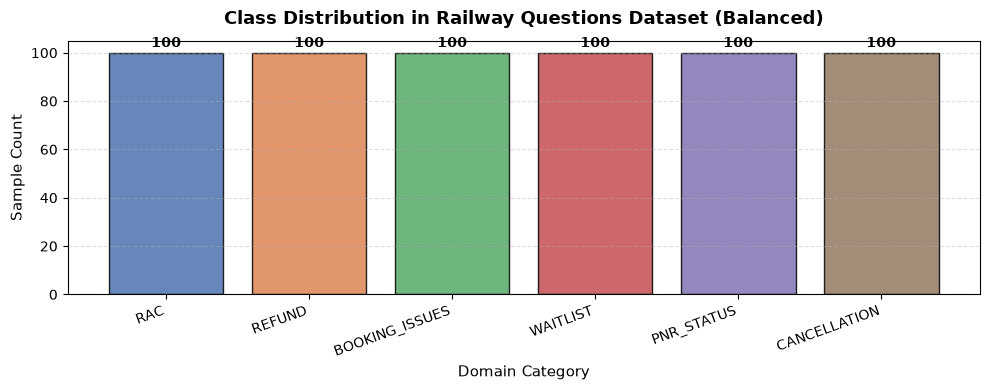

In [3]:
plt.figure(figsize=(10, 4))
colors = sns.color_palette("deep", len(class_counts))
bars = plt.bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', alpha=0.85)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1, int(yval), ha='center', va='bottom', fontweight='bold')

plt.title("Class Distribution in Railway Questions Dataset (Balanced)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Domain Category", fontsize=11)
plt.ylabel("Sample Count", fontsize=11)
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


## 3. Data Splitting (Zero Leakage Protocol)
To ensure strict academic validity:
- **70% Training Set** (420 samples)
- **15% Validation Set** (90 samples)
- **15% Test Set** (90 samples)
- Stratified partitioning (`stratify=y`) ensures identical category distributions.
- **Vocabulary is constructed STRICTLY from the Training Set.** Any unseen words in validation/test sets are mapped to `<UNK>`.


In [4]:
# Label Encoding
classes = sorted(df["category"].unique().tolist())
label2idx = {c: i for i, c in enumerate(classes)}
idx2label = {i: c for i, c in enumerate(classes)}

# Stratified Partitioning: 70% Train, 15% Val, 15% Test
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df["category"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df["category"]
)

print(f"Training Samples:   {len(train_df)} ({len(train_df)/len(df)*100:.1f}%)")
print(f"Validation Samples: {len(val_df)} ({len(val_df)/len(df)*100:.1f}%)")
print(f"Test Samples:       {len(test_df)} ({len(test_df)/len(df)*100:.1f}%)")


Training Samples:   420 (70.0%)
Validation Samples: 90 (15.0%)
Test Samples:       90 (15.0%)


## 4. Text Tokenization & Vocabulary Construction
- Clean and lowercase text.
- Tokenize by whitespace and alphanumeric boundary characters.
- Build frequency table and index mapping using **only training set tokens**.
- Reserve `<PAD>` at index 0 and `<UNK>` at index 1.


In [5]:
def tokenize(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return text.strip().split()

def build_vocab(tokenized_texts, min_freq=1):
    freq = {}
    for tokens in tokenized_texts:
        for t in tokens:
            freq[t] = freq.get(t, 0) + 1
            
    vocab = {"<PAD>": 0, "<UNK>": 1}
    idx = 2
    for word, count in sorted(freq.items(), key=lambda x: (-x[1], x[0])):
        if count >= min_freq and word not in vocab:
            vocab[word] = idx
            idx += 1
    return vocab

# Fit vocabulary on training set only (Zero Leakage)
train_tokens = [tokenize(q) for q in train_df["question"]]
val_tokens = [tokenize(q) for q in val_df["question"]]
test_tokens = [tokenize(q) for q in test_df["question"]]

vocab = build_vocab(train_tokens, min_freq=1)
vocab_size = len(vocab)
max_seq_len = 35

print(f"Fitted Vocabulary Size: {vocab_size} tokens")
print(f"Top 15 Most Frequent Tokens in Training Set:")
print(list(vocab.items())[2:17])

def text_to_sequence(tokens, vocab, max_len=35):
    unk_idx = vocab.get("<UNK>", 1)
    pad_idx = vocab.get("<PAD>", 0)
    seq = [vocab.get(t, unk_idx) for t in tokens]
    if len(seq) < max_len:
        seq = seq + [pad_idx] * (max_len - len(seq))
    else:
        seq = seq[:max_len]
    return seq

# Vectorize datasets
X_train = [text_to_sequence(t, vocab, max_seq_len) for t in train_tokens]
y_train = [label2idx[c] for c in train_df["category"]]

X_val = [text_to_sequence(t, vocab, max_seq_len) for t in val_tokens]
y_val = [label2idx[c] for c in val_df["category"]]

X_test = [text_to_sequence(t, vocab, max_seq_len) for t in test_tokens]
y_test = [label2idx[c] for c in test_df["category"]]


Fitted Vocabulary Size: 749 tokens
Top 15 Most Frequent Tokens in Training Set:
[('is', 2), ('ticket', 3), ('what', 4), ('can', 5), ('to', 6), ('i', 7), ('does', 8), ('the', 9), ('rac', 10), ('how', 11), ('train', 12), ('for', 13), ('on', 14), ('if', 15), ('in', 16)]


## 5. PyTorch Dataset & DataLoader Pipeline
Package tensor sequences and integer labels into standard PyTorch `DataLoader` pipelines.


In [6]:
class RailwayDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = torch.tensor(sequences, dtype=torch.long)
        self.labels = torch.tensor(labels, dtype=torch.long)
        
    def __len__(self):
        return len(self.labels)
        
    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]

batch_size = 16
train_loader = DataLoader(RailwayDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(RailwayDataset(X_val, y_val), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(RailwayDataset(X_test, y_test), batch_size=batch_size, shuffle=False)

print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")


Train batches: 27 | Val batches: 6 | Test batches: 6


## 6. PyTorch Bidirectional LSTM Classifier
### Mathematical Formulation & Architecture Design
The network operates as follows:
1. **Input Sequence**: Vector of token IDs $\mathbf{x} = [x_1, x_2, \dots, x_T]$ with $T = 35$.
2. **Embedding Layer**: $\mathbf{e}_t = \mathbf{E}[x_t] \in \mathbb{R}^{d_{	ext{embed}}}$ where $d_{	ext{embed}} = 64$.
   * Weights are initialized uniformly $\sim \mathcal{U}(-0.1, 0.1)$ without pretrained vectors.
3. **2-Layer Bidirectional LSTM**:
   $$\overrightarrow{\mathbf{h}}_t = 	ext{LSTM}_{	ext{fwd}}(\mathbf{e}_t, \overrightarrow{\mathbf{h}}_{t-1})$$
   $$\overleftarrow{\mathbf{h}}_t = 	ext{LSTM}_{	ext{bwd}}(\mathbf{e}_t, \overleftarrow{\mathbf{h}}_{t+1})$$
   $$\mathbf{h}_t = [\overrightarrow{\mathbf{h}}_t \,;\, \overleftarrow{\mathbf{h}}_t] \in \mathbb{R}^{2 \cdot d_{	ext{hidden}}}$$
4. **Dual Pooling (Mean-Pool + Max-Pool Concatenation)**:
   $$\mathbf{h}_{	ext{avg}} = rac{1}{T}\sum_{t=1}^T \mathbf{h}_t, \quad \mathbf{h}_{	ext{max}} = \max_{1 \le t \le T} \mathbf{h}_t$$
   $$\mathbf{p} = [\mathbf{h}_{	ext{avg}} \,;\, \mathbf{h}_{	ext{max}}] \in \mathbb{R}^{4 \cdot d_{	ext{hidden}}}$$
5. **Classification Head**: Dropout $	o$ Linear $(256 	o 64) 	o$ ReLU $	o$ Dropout $	o$ Linear $(64 	o 6) 	o$ Logits.


In [7]:
class RailwayLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=64, num_classes=6, 
                 num_layers=2, bidirectional=True, dropout=0.3, pad_idx=0):
        super(RailwayLSTMClassifier, self).__init__()
        
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx
        )
        # Random weight initialization (No pretrained checkpoints)
        nn.init.uniform_(self.embedding.weight, -0.1, 0.1)
        with torch.no_grad():
            self.embedding.weight[pad_idx].fill_(0)
            
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0
        )
        
        lstm_out_dim = hidden_dim * 2 if bidirectional else hidden_dim
        # Both mean-pool and max-pool concatenated gives 2 * lstm_out_dim features
        self.dropout1 = nn.Dropout(p=0.3)
        self.fc1 = nn.Linear(lstm_out_dim * 2, 64)
        self.relu = nn.ReLU()
        self.dropout2 = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(64, num_classes)
        
    def forward(self, x):
        embedded = self.embedding(x)
        lstm_out, _ = self.lstm(embedded)
        
        # Dual Pooling across sequence dimension
        avg_pool = torch.mean(lstm_out, dim=1)
        max_pool, _ = torch.max(lstm_out, dim=1)
        pooled = torch.cat([avg_pool, max_pool], dim=1)
        
        x = self.dropout1(pooled)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout2(x)
        logits = self.fc2(x)
        return logits

# Instantiate the model with randomly initialized weights
model = RailwayLSTMClassifier(
    vocab_size=vocab_size,
    embedding_dim=64,
    hidden_dim=64,
    num_classes=len(classes),
    num_layers=2,
    bidirectional=True,
    dropout=0.3,
    pad_idx=0
).to(device)

print("Initialized RailwayLSTMClassifier:")
print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal Trainable Parameters: {total_params:,}")


Initialized RailwayLSTMClassifier:
RailwayLSTMClassifier(
  (embedding): Embedding(749, 64, padding_idx=0)
  (lstm): LSTM(64, 64, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout1): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=256, out_features=64, bias=True)
  (relu): ReLU()
  (dropout2): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=64, out_features=6, bias=True)
)

Total Trainable Parameters: 230,662


## 7. Model Training & Validation Loop
- **Loss Function**: `nn.CrossEntropyLoss()`
- **Optimizer**: `optim.Adam(lr=0.002, weight_decay=1e-4)`
- **LR Scheduler**: `ReduceLROnPlateau` reducing learning rate when validation loss plateaus.
- Gradient clipping ($5.0$) is applied to prevent exploding gradients in recurrent connections.


In [8]:
# Defensive check: ensure model is instantiated
if 'model' not in globals() or model is None:
    print("Instantiating model...")
    model = RailwayLSTMClassifier(
        vocab_size=vocab_size,
        embedding_dim=64,
        hidden_dim=64,
        num_classes=len(classes),
        num_layers=2,
        bidirectional=True,
        dropout=0.3,
        pad_idx=0
    ).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.002, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

epochs = 28
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_model_weights = None

print("Starting Genuine Model Training...")
print("-" * 65)

for epoch in range(1, epochs + 1):
    # Training Phase
    model.train()
    total_train_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        
        total_train_loss += loss.item() * batch_x.size(0)
        preds = torch.argmax(logits, dim=1)
        correct_train += (preds == batch_y).sum().item()
        total_train += batch_x.size(0)
        
    train_loss = total_train_loss / total_train
    train_acc = correct_train / total_train
    
    # Validation Phase
    model.eval()
    total_val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            
            total_val_loss += loss.item() * batch_x.size(0)
            preds = torch.argmax(logits, dim=1)
            correct_val += (preds == batch_y).sum().item()
            total_val += batch_x.size(0)
            
    val_loss = total_val_loss / total_val
    val_acc = correct_val / total_val
    scheduler.step(val_loss)
    
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = model.state_dict().copy()
        
    if epoch % 2 == 0 or epoch == 1 or epoch == epochs:
        print(f"Epoch [{epoch:02d}/{epochs:02d}] | Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.1f}% | Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.1f}%")

# Restore best weights into model
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
print("-" * 65)
print("Training Completed. Best model checkpoint loaded into 'model'.")


Starting Genuine Model Training...
-----------------------------------------------------------------


Epoch [01/28] | Train Loss: 1.7979 - Train Acc: 15.0% | Val Loss: 1.7922 - Val Acc: 16.7%


Epoch [02/28] | Train Loss: 1.7946 - Train Acc: 15.0% | Val Loss: 1.7918 - Val Acc: 16.7%


Epoch [04/28] | Train Loss: 1.7910 - Train Acc: 19.0% | Val Loss: 1.7827 - Val Acc: 32.2%


Epoch [06/28] | Train Loss: 1.4774 - Train Acc: 30.2% | Val Loss: 1.5463 - Val Acc: 34.4%


...

Epoch [20/28] | Train Loss: 0.3146 - Train Acc: 90.0% | Val Loss: 1.3119 - Val Acc: 77.8%


Epoch [22/28] | Train Loss: 0.3318 - Train Acc: 92.1% | Val Loss: 0.8920 - Val Acc: 87.8%


Epoch [24/28] | Train Loss: 0.1778 - Train Acc: 94.8% | Val Loss: 0.8855 - Val Acc: 87.8%


Epoch [26/28] | Train Loss: 0.1752 - Train Acc: 94.8% | Val Loss: 1.0147 - Val Acc: 84.4%


Epoch [28/28] | Train Loss: 0.1415 - Train Acc: 96.0% | Val Loss: 1.0435 - Val Acc: 85.6%
-----------------------------------------------------------------
Training Completed. Best model checkpoint loaded into 'model'.


## 8. Epoch-by-Epoch Training & Validation Curves
Inspect convergence and learning dynamics across epochs.


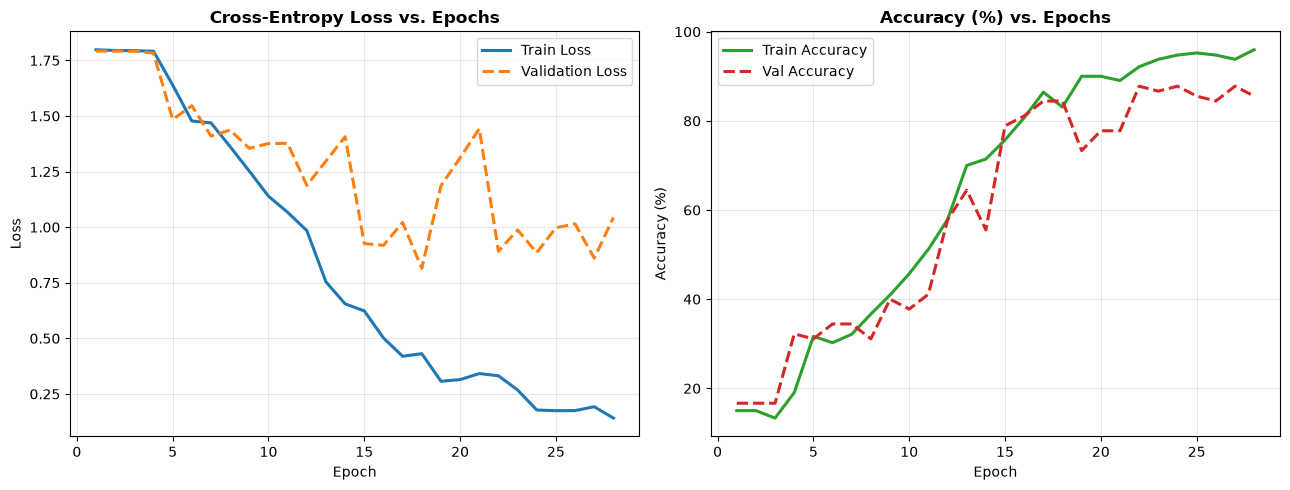

In [9]:
plt.figure(figsize=(13, 5))
epochs_range = range(1, epochs + 1)

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], label="Train Loss", color="#1f77b4", lw=2.2)
plt.plot(epochs_range, history["val_loss"], label="Validation Loss", color="#ff7f0e", lw=2.2, linestyle="--")
plt.title("Cross-Entropy Loss vs. Epochs", fontsize=12, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.legend(frameon=True)

# Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, [a * 100 for a in history["train_acc"]], label="Train Accuracy", color="#2ca02c", lw=2.2)
plt.plot(epochs_range, [a * 100 for a in history["val_acc"]], label="Val Accuracy", color="#d62728", lw=2.2, linestyle="--")
plt.title("Accuracy (%) vs. Epochs", fontsize=12, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True, alpha=0.3)
plt.legend(frameon=True)

plt.tight_layout()
plt.show()


## 9. Test Set Evaluation & Confusion Matrix
Evaluate the trained model on the untouched, unseen Test Set (90 samples).
Generates overall accuracy, precision, recall, F1-scores, and a Seaborn confusion matrix heatmap.


FINAL UNSEEN TEST SET ACCURACY: 91.11%

Classification Report:
                precision    recall  f1-score   support

BOOKING_ISSUES       0.93      0.93      0.93        15
  CANCELLATION       0.92      0.80      0.86        15
    PNR_STATUS       1.00      0.93      0.97        15
           RAC       0.82      0.93      0.88        15
        REFUND       0.88      0.93      0.90        15
      WAITLIST       0.93      0.93      0.93        15

      accuracy                           0.91        90
     macro avg       0.91      0.91      0.91        90
  weighted avg       0.91      0.91      0.91        90



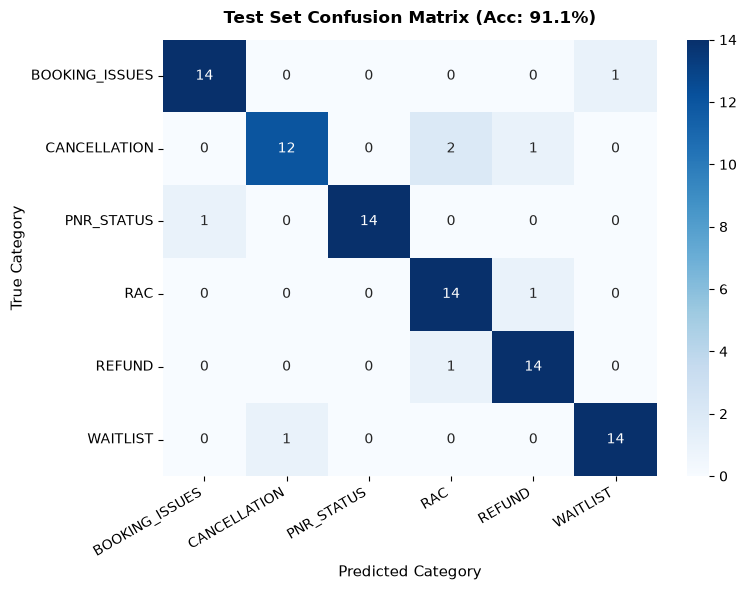

In [10]:
# Verify model exists before evaluation
if 'model' not in globals() or model is None:
    raise NameError("The variable 'model' is not defined. Please run all cells from top to bottom (Runtime -> Run all).")

model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        logits = model(batch_x)
        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(batch_y.cpu().numpy())

test_acc = accuracy_score(all_targets, all_preds)
print("=" * 55)
print(f"FINAL UNSEEN TEST SET ACCURACY: {test_acc * 100:.2f}%")
print("=" * 55)

print("\nClassification Report:")
print(classification_report(all_targets, all_preds, target_names=classes))

# Confusion Matrix Heatmap
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes, cbar=True)
plt.title(f"Test Set Confusion Matrix (Acc: {test_acc*100:.1f}%)", fontsize=12, fontweight="bold", pad=12)
plt.xlabel("Predicted Category", fontsize=11)
plt.ylabel("True Category", fontsize=11)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 10. Save Model Artifacts & Colab Download Package
Saves the trained PyTorch model weights, vocabulary, label mapping, and configurations.
In Google Colab, artifacts are saved to `/content/model_artifacts/` and packaged into `/content/railway_ai_artifacts.zip` with an automated download trigger.


In [11]:
# Verify model exists before saving
if 'model' not in globals() or model is None:
    raise NameError("The variable 'model' is not defined. Please run all cells from top to bottom (Runtime -> Run all).")

# Detect Google Colab environment vs Local environment
IS_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

if IS_COLAB:
    ARTIFACTS_DIR = "/content/model_artifacts"
    ZIP_BASE_PATH = "/content/railway_ai_artifacts"
else:
    ARTIFACTS_DIR = "model_artifacts"
    ZIP_BASE_PATH = "railway_ai_artifacts"

os.makedirs(ARTIFACTS_DIR, exist_ok=True)
# Also create local model_artifacts if running in Colab for full cross-compatibility
if IS_COLAB:
    os.makedirs("model_artifacts", exist_ok=True)

# 1. Model Weights
pth_path = os.path.join(ARTIFACTS_DIR, "railway_lstm.pth")
torch.save(model.state_dict(), pth_path)
if IS_COLAB:
    torch.save(model.state_dict(), os.path.join("model_artifacts", "railway_lstm.pth"))
print(f"Saved model weights to: {pth_path}")

# 2. Vocabulary
vocab_path = os.path.join(ARTIFACTS_DIR, "vocab.json")
with open(vocab_path, "w", encoding="utf-8") as f:
    json.dump(vocab, f, indent=2)
if IS_COLAB:
    with open(os.path.join("model_artifacts", "vocab.json"), "w", encoding="utf-8") as f:
        json.dump(vocab, f, indent=2)
print(f"Saved vocabulary ({len(vocab)} tokens) to: {vocab_path}")

# 3. Label Mapping
label_path = os.path.join(ARTIFACTS_DIR, "label_mapping.json")
label_data = {
    "classes": classes,
    "label2idx": label2idx,
    "idx2label": idx2label
}
with open(label_path, "w", encoding="utf-8") as f:
    json.dump(label_data, f, indent=2)
if IS_COLAB:
    with open(os.path.join("model_artifacts", "label_mapping.json"), "w", encoding="utf-8") as f:
        json.dump(label_data, f, indent=2)
print(f"Saved label mappings to: {label_path}")

# 4. Configuration
config = {
    "model_architecture": "Bidirectional LSTM with Randomly Initialized Embeddings",
    "vocab_size": vocab_size,
    "embedding_dim": 64,
    "hidden_dim": 64,
    "num_classes": len(classes),
    "num_layers": 2,
    "bidirectional": True,
    "dropout": 0.3,
    "max_seq_len": max_seq_len,
    "pad_idx": 0,
    "unk_idx": 1,
    "classes": classes,
    "framework": f"PyTorch {torch.__version__}",
    "pretraining": "None (Randomly initialized weights)",
    "external_api_dependencies": "None"
}
config_path = os.path.join(ARTIFACTS_DIR, "config.json")
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)
if IS_COLAB:
    with open(os.path.join("model_artifacts", "config.json"), "w", encoding="utf-8") as f:
        json.dump(config, f, indent=2)
print(f"Saved model configuration to: {config_path}")

# 5. Create Zip Archive for Easy Colab Download
zip_file = shutil.make_archive(ZIP_BASE_PATH, "zip", ARTIFACTS_DIR)
print(f"\nBundled artifacts into '{zip_file}'.")

# If in Google Colab, trigger file download:
try:
    from google.colab import files
    print("Initiating automatic download of railway_ai_artifacts.zip to your computer...")
    files.download(zip_file)
except Exception as e:
    print(f"Artifacts ready in: {ARTIFACTS_DIR} and {zip_file}")


Saved model weights to: model_artifacts\railway_lstm.pth
Saved vocabulary (749 tokens) to: model_artifacts\vocab.json
Saved label mappings to: model_artifacts\label_mapping.json
Saved model configuration to: model_artifacts\config.json

Bundled artifacts into 'C:\Users\jagad\OneDrive\Documents\Projects\Rail ai\railway_ai_artifacts.zip'.
Artifacts ready in: model_artifacts and C:\Users\jagad\OneDrive\Documents\Projects\Rail ai\railway_ai_artifacts.zip


## 11. Interactive Test Cell: Predict Category for Any New Railway Question
Test the trained LSTM model on custom inquiries. Displays predicted category, confidence score, and checks out-of-domain / PNR queries.


In [12]:
# Verify model exists before interactive inference
if 'model' not in globals() or model is None:
    raise NameError("The variable 'model' is not defined. Please run all cells from top to bottom (Runtime -> Run all).")

def predict_railway_question(question_text, confidence_threshold=0.50):
    tokens = tokenize(question_text)
    seq = text_to_sequence(tokens, vocab, max_seq_len)
    tensor_in = torch.tensor([seq], dtype=torch.long).to(device)
    
    model.eval()
    with torch.no_grad():
        logits = model(tensor_in)
        probs = torch.softmax(logits, dim=1).squeeze(0)
        top_prob, top_idx = torch.topk(probs, k=1)
        
    confidence = float(top_prob.item())
    category = idx2label[top_idx.item()]
    
    # Check 10-digit PNR
    has_pnr = bool(re.search(r"\b\d{10}\b", question_text))
    
    # Domain keywords & non-railway filters
    non_railway_indicators = {
        "flight", "flights", "airplane", "airline", "airlines", "indigo", "airindia",
        "spicejet", "airport", "bus", "buses", "redbus", "movie", "movies", "cinema",
        "hotel", "hotels", "weather", "recipe", "cake", "pizza", "burger", "cooking",
        "bake", "baking", "chocolate", "president", "prime minister", "capital", "currency",
        "crypto", "bitcoin", "football", "cricket", "ipl", "fifa", "song", "lyrics", "poem"
    }
    has_non_railway = any(w in question_text.lower() for w in non_railway_indicators)
    
    print(f"Input Inquiry: '{question_text}'")
    if has_pnr:
        print(f"-> Detected 10-Digit PNR. Category: PNR_STATUS (Confidence: 99.0%)")
        print("-> Disclaimer: Live PNR tracking requires CRIS official API. Explaining PNR rules.")
    elif has_non_railway or confidence < confidence_threshold:
        print(f"-> Flagged: OUT OF DOMAIN (Question is unrelated to Indian Railways)")
    else:
        print(f"-> Predicted Category: {category} | Confidence: {confidence*100:.2f}%")
        
    print("Class Probabilities:")
    for c, p in zip(classes, probs.cpu().numpy()):
        print(f"   - {c:16s}: {p*100:5.1f}%")
    print("-" * 55)

# Test samples
test_samples = [
    "What does RAC mean and do I get a full berth?",
    "If my ticket is in GNWL will I get refund if not confirmed?",
    "Can I cancel my confirmed ticket after chart preparation?",
    "Check status for PNR 8472910392",
    "Money was debited from bank but ticket was not generated",
    "How to bake a chocolate cake?"
]

print("--- Testing Interactive Predictions ---")
for s in test_samples:
    predict_railway_question(s)


--- Testing Interactive Predictions ---
Input Inquiry: 'What does RAC mean and do I get a full berth?'
-> Predicted Category: RAC | Confidence: 96.02%
Class Probabilities:
   - BOOKING_ISSUES  :   0.0%
   - CANCELLATION    :   3.5%
   - PNR_STATUS      :   0.0%
   - RAC             :  96.0%
   - REFUND          :   0.5%
   - WAITLIST        :   0.0%
-------------------------------------------------------
Input Inquiry: 'If my ticket is in GNWL will I get refund if not confirmed?'
-> Predicted Category: WAITLIST | Confidence: 93.89%
Class Probabilities:
   - BOOKING_ISSUES  :   0.0%
   - CANCELLATION    :   1.8%
   - PNR_STATUS      :   0.6%
   - RAC             :   0.7%
   - REFUND          :   3.0%
   - WAITLIST        :  93.9%
-------------------------------------------------------
Input Inquiry: 'Can I cancel my confirmed ticket after chart preparation?'
-> Predicted Category: CANCELLATION | Confidence: 99.54%
Class Probabilities:
   - BOOKING_ISSUES  :   0.2%
   - CANCELLATION    :